In [ ]:
# Install required packages
!pip install pandas numpy matplotlib seaborn scikit-learn nltk


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from imblearn.over_sampling import SMOTE
import re
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
# Set the file path
file_path = '/content/drive/MyDrive/Dataset.csv'

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Drop the 'Unnamed: 0' column if it exists (often created when saving from Excel/CSV)
if 'Unnamed: 0' in df.columns:
    df.drop('Unnamed: 0', axis=1, inplace=True)

# Display the first 5 rows
df.head()

,text,Emotion
0,i seriously hate one subject to death but now ...,hate
1,im so full of life i feel appalled,neutral
2,i sit here to write i start to dig out my feel...,neutral
3,ive been really angry with r and i feel like a...,anger
4,i feel suspicious if there is no one outside l...,neutral


In [22]:
# Check the shape of the dataset (rows, columns)
df.shape


(839555, 2)

In [23]:
# See how many missing values are in each column
df.isnull().sum()

,0
text,0
Emotion,0


In [24]:
# Look at how many samples we have for each emotion
df['Emotion'].value_counts()

,count
Emotion,
neutral,674538
love,39553
happiness,27175
sadness,17481
relief,16729
hate,15267
anger,12336
fun,10075
enthusiasm,9304


In [25]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text, re.I|re.A)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess_text)

label_encoder = LabelEncoder()
df['encoded_emotion'] = label_encoder.fit_transform(df['Emotion'])


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE

# Split data into train/test
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['encoded_emotion'],
    test_size=0.3,
    random_state=42,
    stratify=df['encoded_emotion']
)

# TF-IDF with N-grams
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 3),      # (1,3) → unigrams + bigrams + trigrams
    sublinear_tf=True,       # use log scaling for term frequency
    min_df=3,                # ignore very rare terms
    max_df=0.9               # ignore overly common terms
)

# Fit TF-IDF on train and transform both sets
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Apply SMOTE to handle imbalance
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_tfidf, y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After SMOTE:", np.bincount(y_train_balanced))
print("TF-IDF features shape:", X_train_tfidf.shape)


Before SMOTE: [  8635     88   3879   6513   7053  19022  10687  27687 472176  11710
  12237   4868   3133]
After SMOTE: [472176 472176 472176 472176 472176 472176 472176 472176 472176 472176
 472176 472176 472176]
TF-IDF features shape: (587688, 15000)


In [27]:
log_reg = LogisticRegression(max_iter=500, n_jobs=-1)
log_reg.fit(X_train_balanced, y_train_balanced)

y_pred_lr = log_reg.predict(X_test_tfidf)

print("=== Logistic Regression Report ===")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))


=== Logistic Regression Report ===
              precision    recall  f1-score   support

       anger       0.98      0.97      0.98      3701
     boredom       0.40      0.95      0.56        38
       empty       0.98      0.97      0.97      1663
  enthusiasm       0.99      0.98      0.99      2791
         fun       0.92      0.95      0.94      3022
   happiness       0.99      0.99      0.99      8153
        hate       0.99      0.99      0.99      4580
        love       0.98      0.99      0.98     11866
     neutral       1.00      1.00      1.00    202362
      relief       0.98      0.97      0.98      5019
     sadness       1.00      0.97      0.98      5244
    surprise       0.99      0.98      0.99      2086
       worry       0.93      0.99      0.96      1342

    accuracy                           0.99    251867
   macro avg       0.93      0.98      0.95    251867
weighted avg       0.99      0.99      0.99    251867



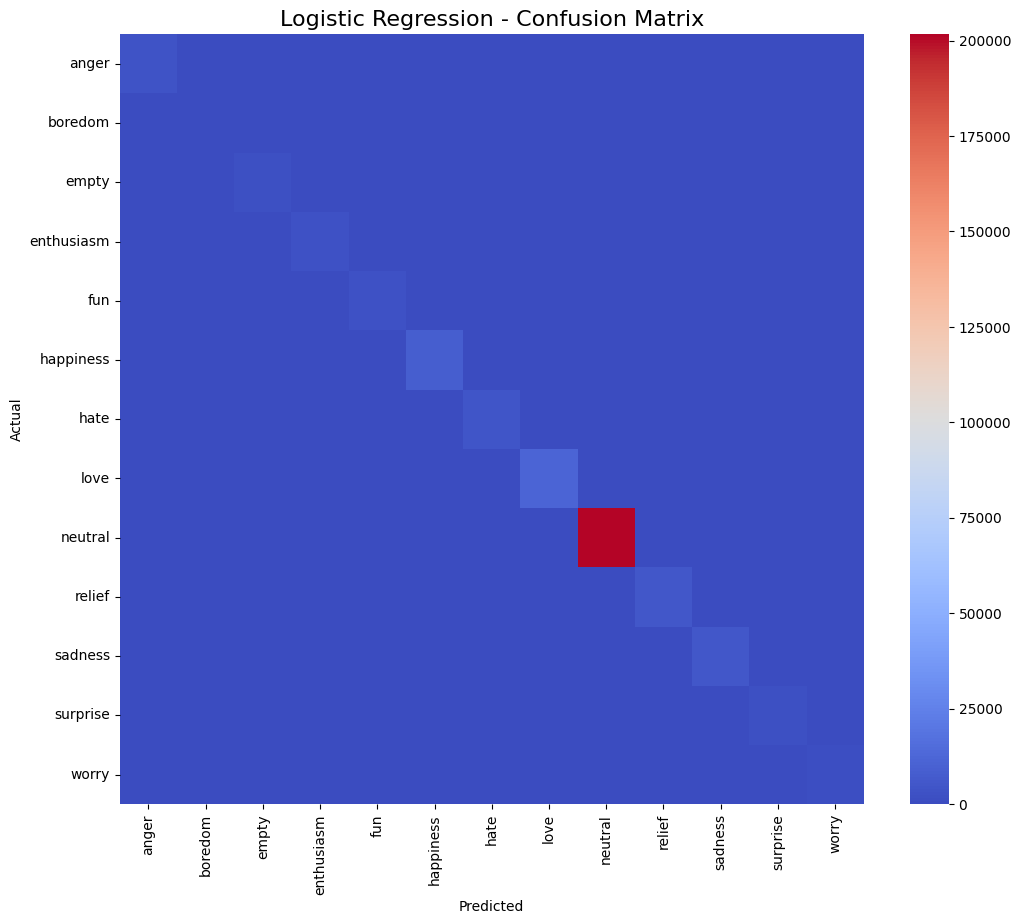

Accuracy: 0.9932186431727856
F1 Score: 0.9932712676417244
Precision: 0.9933840344539886
Recall: 0.9932186431727856


In [28]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_lr,
    annot=False,
    cmap="coolwarm",  # multi-color scheme
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Logistic Regression - Confusion Matrix", fontsize=16)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr, average="weighted"))
print("Precision:", precision_score(y_test, y_pred_lr, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_lr, average="weighted"))


In [29]:
svm_model = LinearSVC(max_iter=2000)
svm_model.fit(X_train_balanced, y_train_balanced)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("=== Support Vector Machine Report ===")
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_))


=== Support Vector Machine Report ===
              precision    recall  f1-score   support

       anger       0.98      0.98      0.98      3701
     boredom       0.90      0.95      0.92        38
       empty       0.98      0.99      0.98      1663
  enthusiasm       0.99      0.99      0.99      2791
         fun       0.94      0.98      0.96      3022
   happiness       1.00      0.99      0.99      8153
        hate       0.99      0.99      0.99      4580
        love       0.98      0.99      0.99     11866
     neutral       1.00      1.00      1.00    202362
      relief       0.98      0.98      0.98      5019
     sadness       0.99      0.98      0.99      5244
    surprise       0.99      0.99      0.99      2086
       worry       0.95      0.99      0.97      1342

    accuracy                           0.99    251867
   macro avg       0.98      0.98      0.98    251867
weighted avg       1.00      0.99      0.99    251867



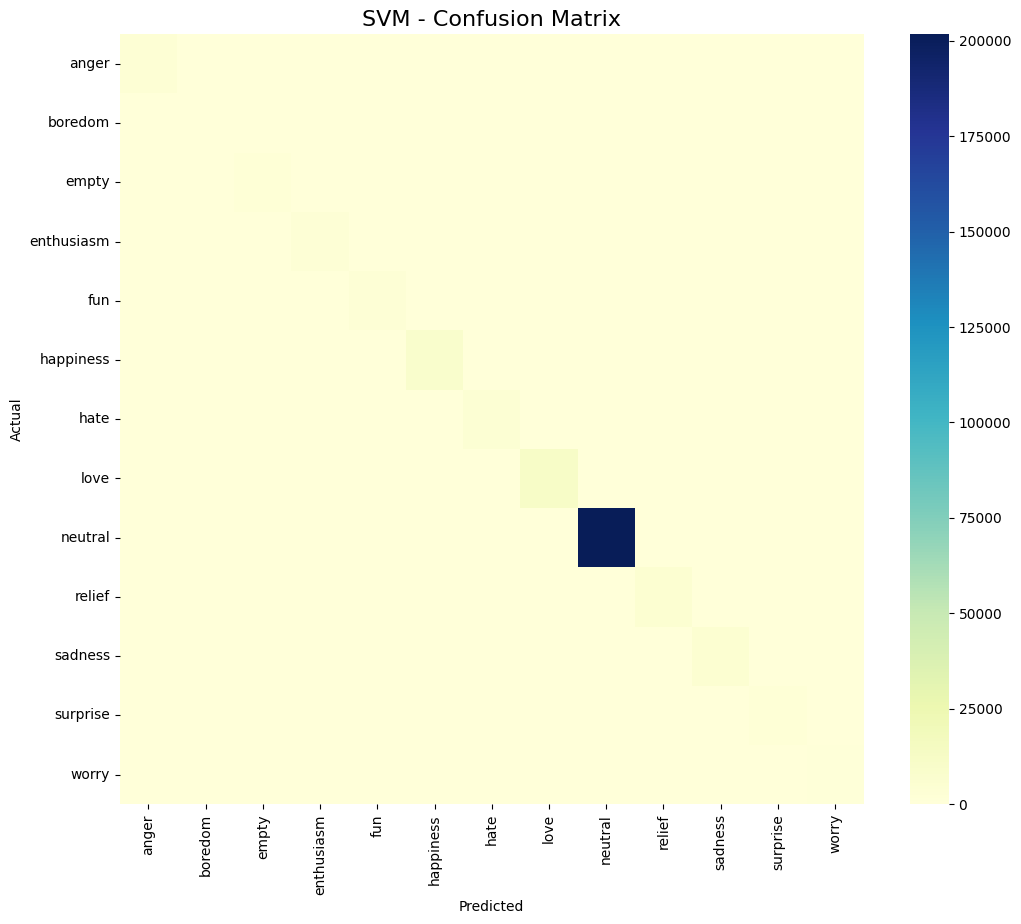

Accuracy: 0.9949775079704765
F1 Score: 0.9949932699840758
Precision: 0.9950282075195488
Recall: 0.9949775079704765


In [30]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_svm,
    annot=False,
    cmap="YlGnBu",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("SVM - Confusion Matrix", fontsize=16)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm, average="weighted"))
print("Precision:", precision_score(y_test, y_pred_svm, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_svm, average="weighted"))


In [31]:
import joblib

joblib.dump(log_reg, "logistic_regression_model.pkl")
joblib.dump(svm_model, "svm_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Models, vectorizer, and encoder saved successfully!")


Models, vectorizer, and encoder saved successfully!
